In [1]:
import pandas as pd
import os

# Load HAM10000 metadata
metadata_path = "../HAM10000_metadata.csv"

df = pd.read_csv(metadata_path)

print("Dataset loaded successfully!")
print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

df.head()

Dataset loaded successfully!
Number of records: 10015
Number of columns: 7


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


Disease class distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


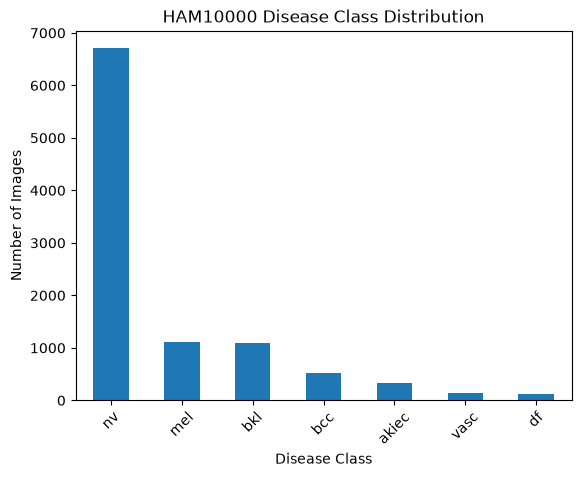

In [2]:
# Count images in each disease class
print("Disease class distribution:")
print(df["dx"].value_counts())

# Plot the distribution
import matplotlib.pyplot as plt

df["dx"].value_counts().plot(kind="bar")

plt.title("HAM10000 Disease Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

In [3]:
import os

# Main project folder
project_dir = r"C:\Users\muvva\Downloads\DermaVision"

# Dataset folder
dataset_dir = os.path.join(project_dir, "dataset")

print("Project folder exists:", os.path.exists(project_dir))
print("Dataset folder exists:", os.path.exists(dataset_dir))

print("\nFolders inside dataset:")

if os.path.exists(dataset_dir):
    print(os.listdir(dataset_dir))

Project folder exists: True
Dataset folder exists: True

Folders inside dataset:
[]


In [4]:
import os

print("Current working folder:")
print(os.getcwd())

print("\nFolders/files here:")
print(os.listdir())

Current working folder:
c:\Users\muvva\Downloads\DermaVision\notebooks

Folders/files here:
['01_dataset_analysis.ipynb', 'dermavision_best_model.keras']


In [5]:
import os

print(os.listdir("../dataset"))

[]


In [6]:
import os

image_dir1 = "../HAM10000_images_part_1"
image_dir2 = "../HAM10000_images_part_2"

images1 = [f for f in os.listdir(image_dir1) if f.lower().endswith(".jpg")]
images2 = [f for f in os.listdir(image_dir2) if f.lower().endswith(".jpg")]

print("Images in part 1:", len(images1))
print("Images in part 2:", len(images2))
print("Total image files:", len(images1) + len(images2))

Images in part 1: 5000
Images in part 2: 5015
Total image files: 10015


In [7]:
import os

print(os.path.abspath("../dataset"))

c:\Users\muvva\Downloads\DermaVision\dataset


In [8]:
import os

print(os.path.exists("../dataset"))
print(os.listdir(".."))

True
['dataset', 'HAM10000_images_part_1', 'HAM10000_images_part_2', 'HAM10000_metadata.csv', 'hmnist_28_28_L.csv', 'hmnist_28_28_RGB.csv', 'hmnist_8_8_L.csv', 'hmnist_8_8_RGB.csv', 'notebooks', 'venv']


In [9]:
import os
import pandas as pd

# Paths to image folders
image_dir1 = "../dataset/HAM10000_images_part_1"
image_dir2 = "../dataset/HAM10000_images_part_2"

# Take first 5 image IDs from metadata
sample_ids = df["image_id"].head(5)

print("Sample image IDs:")
print(sample_ids.tolist())

# Find the actual image files
for image_id in sample_ids:
    
    file_name = image_id + ".jpg"
    
    path1 = os.path.join(image_dir1, file_name)
    path2 = os.path.join(image_dir2, file_name)
    
    if os.path.exists(path1):
        print(image_id, "-> Part 1")
    elif os.path.exists(path2):
        print(image_id, "-> Part 2")
    else:
        print(image_id, "-> NOT FOUND")

Sample image IDs:
['ISIC_0027419', 'ISIC_0025030', 'ISIC_0026769', 'ISIC_0025661', 'ISIC_0031633']
ISIC_0027419 -> NOT FOUND
ISIC_0025030 -> NOT FOUND
ISIC_0026769 -> NOT FOUND
ISIC_0025661 -> NOT FOUND
ISIC_0031633 -> NOT FOUND


In [10]:
import os

dataset_path = r"C:\Users\muvva\Downloads\DermaVision\dataset"

print("Dataset exists:", os.path.exists(dataset_path))
print("Dataset contents:")
print(os.listdir(dataset_path))

Dataset exists: True
Dataset contents:
[]


In [11]:
import os

project_path = r"C:\Users\muvva\Downloads\DermaVision"

print("Project folders/files:")
print(os.listdir(project_path))

Project folders/files:
['dataset', 'HAM10000_images_part_1', 'HAM10000_images_part_2', 'HAM10000_metadata.csv', 'hmnist_28_28_L.csv', 'hmnist_28_28_RGB.csv', 'hmnist_8_8_L.csv', 'hmnist_8_8_RGB.csv', 'notebooks', 'venv']


In [12]:
import os

image_dir1 = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_1"
image_dir2 = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_2"

print("Part 1 exists:", os.path.exists(image_dir1))
print("Part 2 exists:", os.path.exists(image_dir2))

print("\nFirst 5 files in Part 1:")
print(os.listdir(image_dir1)[:5])

print("\nFirst 5 files in Part 2:")
print(os.listdir(image_dir2)[:5])

Part 1 exists: True
Part 2 exists: True

First 5 files in Part 1:
['ISIC_0024306.jpg', 'ISIC_0024307.jpg', 'ISIC_0024308.jpg', 'ISIC_0024309.jpg', 'ISIC_0024310.jpg']

First 5 files in Part 2:
['ISIC_0029306.jpg', 'ISIC_0029307.jpg', 'ISIC_0029308.jpg', 'ISIC_0029309.jpg', 'ISIC_0029310.jpg']


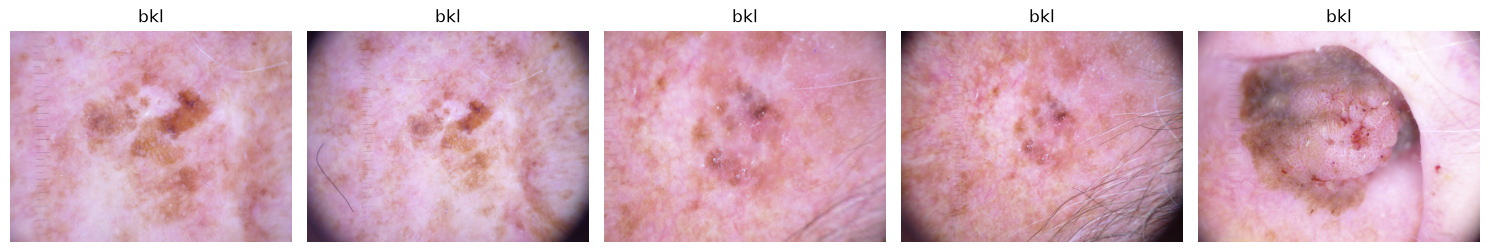

In [13]:
import matplotlib.pyplot as plt
from PIL import Image

# Take 5 sample records
sample_data = df.head(5)

plt.figure(figsize=(15, 8))

for i, (_, row) in enumerate(sample_data.iterrows()):

    image_id = row["image_id"]
    disease = row["dx"]

    file_name = image_id + ".jpg"

    # Check Part 1 first
    path1 = os.path.join(image_dir1, file_name)

    # Otherwise check Part 2
    path2 = os.path.join(image_dir2, file_name)

    if os.path.exists(path1):
        image_path = path1
    else:
        image_path = path2

    # Load image
    image = Image.open(image_path)

    # Display
    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(disease)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
from PIL import Image
import os

# Check properties of the first 5 images

sample_data = df.head(5)

for _, row in sample_data.iterrows():

    image_id = row["image_id"]
    file_name = image_id + ".jpg"

    path1 = os.path.join(image_dir1, file_name)
    path2 = os.path.join(image_dir2, file_name)

    if os.path.exists(path1):
        image_path = path1
    else:
        image_path = path2

    image = Image.open(image_path)

    print("Image ID:", image_id)
    print("Size:", image.size)
    print("Mode:", image.mode)
    print("Format:", image.format)
    print("-------------------------")

Image ID: ISIC_0027419
Size: (600, 450)
Mode: RGB
Format: JPEG
-------------------------
Image ID: ISIC_0025030
Size: (600, 450)
Mode: RGB
Format: JPEG
-------------------------
Image ID: ISIC_0026769
Size: (600, 450)
Mode: RGB
Format: JPEG
-------------------------
Image ID: ISIC_0025661
Size: (600, 450)
Mode: RGB
Format: JPEG
-------------------------
Image ID: ISIC_0031633
Size: (600, 450)
Mode: RGB
Format: JPEG
-------------------------


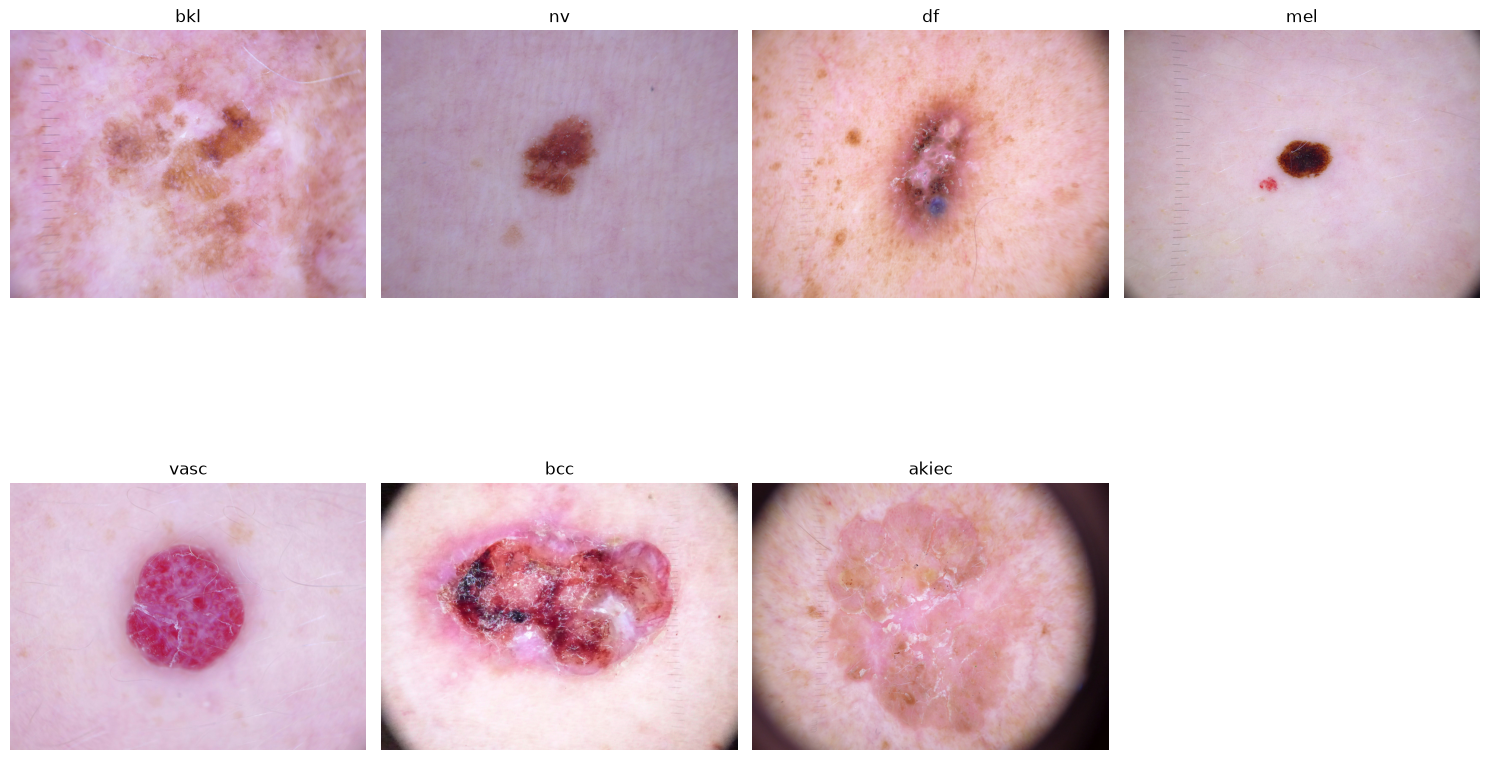

In [15]:
import matplotlib.pyplot as plt
from PIL import Image
import os

classes = df["dx"].unique()

plt.figure(figsize=(15, 10))

for i, disease in enumerate(classes):

    row = df[df["dx"] == disease].iloc[0]

    image_id = row["image_id"]
    file_name = image_id + ".jpg"

    path1 = os.path.join(image_dir1, file_name)
    path2 = os.path.join(image_dir2, file_name)

    if os.path.exists(path1):
        image_path = path1
    else:
        image_path = path2

    image = Image.open(image_path)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(disease)
    plt.axis("off")

plt.tight_layout()
plt.show()

Original size: (600, 450)
New size: (224, 224)
Array shape: (224, 224, 3)
Minimum pixel value: 0.18823529411764706
Maximum pixel value: 1.0


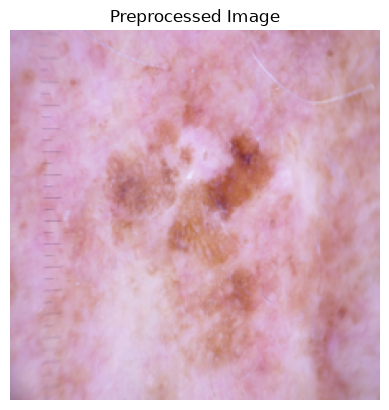

In [16]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Take the first image
row = df.iloc[0]

image_id = row["image_id"]
file_name = image_id + ".jpg"

# Find the image
path1 = os.path.join(image_dir1, file_name)
path2 = os.path.join(image_dir2, file_name)

if os.path.exists(path1):
    image_path = path1
else:
    image_path = path2

# Load image
image = Image.open(image_path).convert("RGB")

print("Original size:", image.size)

# Resize
image_resized = image.resize((224, 224))

# Convert to NumPy array
image_array = np.array(image_resized)

# Normalize pixel values
image_normalized = image_array / 255.0

print("New size:", image_resized.size)
print("Array shape:", image_normalized.shape)
print("Minimum pixel value:", image_normalized.min())
print("Maximum pixel value:", image_normalized.max())

# Display processed image
plt.imshow(image_normalized)
plt.title("Preprocessed Image")
plt.axis("off")
plt.show()

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def check_image_quality(image_path):
    
    image = cv2.imread(image_path)
    
    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    
    # Brightness
    brightness = np.mean(gray)
    
    # Contrast
    contrast = np.std(gray)
    
    # Sharpness / blur measurement
    sharpness = cv2.Laplacian(gray, cv2.CV_64F).var()
    
    return brightness, contrast, sharpness


# Check first 5 images
sample_data = df.head(5)

for _, row in sample_data.iterrows():

    image_id = row["image_id"]
    file_name = image_id + ".jpg"

    path1 = os.path.join(image_dir1, file_name)
    path2 = os.path.join(image_dir2, file_name)

    if os.path.exists(path1):
        image_path = path1
    else:
        image_path = path2

    brightness, contrast, sharpness = check_image_quality(image_path)

    print("Image:", image_id)
    print("Brightness:", round(brightness, 2))
    print("Contrast:", round(contrast, 2))
    print("Sharpness:", round(sharpness, 2))
    print("-------------------------")

Image: ISIC_0027419
Brightness: 178.64
Contrast: 18.18
Sharpness: 62.19
-------------------------
Image: ISIC_0025030
Brightness: 171.04
Contrast: 34.78
Sharpness: 68.73
-------------------------
Image: ISIC_0026769
Brightness: 175.68
Contrast: 16.6
Sharpness: 50.29
-------------------------
Image: ISIC_0025661
Brightness: 160.16
Contrast: 33.44
Sharpness: 220.25
-------------------------
Image: ISIC_0031633
Brightness: 183.03
Contrast: 40.0
Sharpness: 53.11
-------------------------


In [18]:
import os
import cv2
import numpy as np
import pandas as pd

# Image folders
image_dir1 = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_1"
image_dir2 = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_2"

# Get all image paths
image_paths = []

for f in os.listdir(image_dir1):
    if f.lower().endswith(".jpg"):
        image_paths.append(os.path.join(image_dir1, f))

for f in os.listdir(image_dir2):
    if f.lower().endswith(".jpg"):
        image_paths.append(os.path.join(image_dir2, f))

print("Total images:", len(image_paths))

Total images: 10015


In [19]:
quality_results = []

# Analyze first 500 images
sample_paths = image_paths[:500]

for path in sample_paths:
    img = cv2.imread(path)

    if img is None:
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    blur_score = cv2.Laplacian(gray, cv2.CV_64F).var()
    brightness = np.mean(gray)
    contrast = np.std(gray)

    height, width = img.shape[:2]

    quality_results.append({
        "image": os.path.basename(path),
        "width": width,
        "height": height,
        "blur_score": blur_score,
        "brightness": brightness,
        "contrast": contrast
    })

quality_df = pd.DataFrame(quality_results)

print("Quality analysis completed!")
print("Images analyzed:", len(quality_df))

quality_df.head()


Quality analysis completed!
Images analyzed: 500


,image,width,height,blur_score,brightness,contrast
0,ISIC_0024306.jpg,600,450,43.876503,146.754770,31.016334
1,ISIC_0024307.jpg,600,450,53.289048,152.554907,18.567454
2,ISIC_0024308.jpg,600,450,85.947015,153.042381,49.687620
3,ISIC_0024309.jpg,600,450,30.222626,134.099256,23.000077
4,ISIC_0024310.jpg,600,450,156.135217,153.591919,31.513469


In [20]:
print("Quality Statistics")
print("===================")

print("\nBlur:")
print(quality_df["blur_score"].describe())

print("\nBrightness:")
print(quality_df["brightness"].describe())

print("\nContrast:")
print(quality_df["contrast"].describe())

Quality Statistics

Blur:
count    500.000000
mean      75.274069
std       66.992630
min        9.136588
25%       35.994260
50%       50.932915
75%       94.721740
max      569.217782
Name: blur_score, dtype: float64

Brightness:
count    500.000000
mean     156.577476
std       18.887603
min       97.102952
25%      144.533862
50%      156.060354
75%      169.254518
max      216.810019
Name: brightness, dtype: float64

Contrast:
count    500.000000
mean      26.277644
std       10.652968
min        6.319037
25%       18.826072
50%       24.421251
75%       31.086953
max       72.327770
Name: contrast, dtype: float64


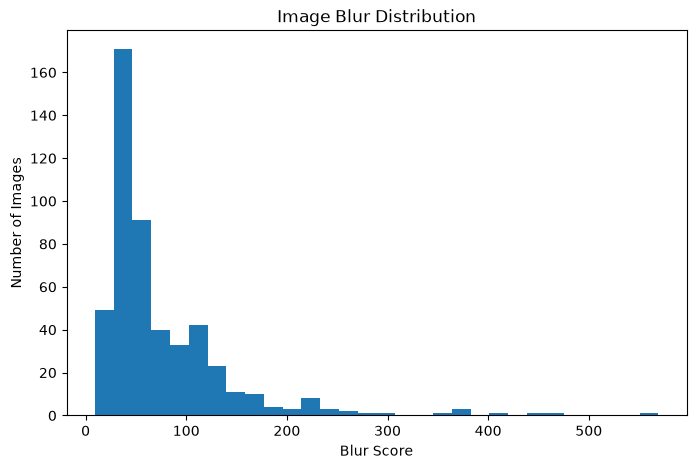

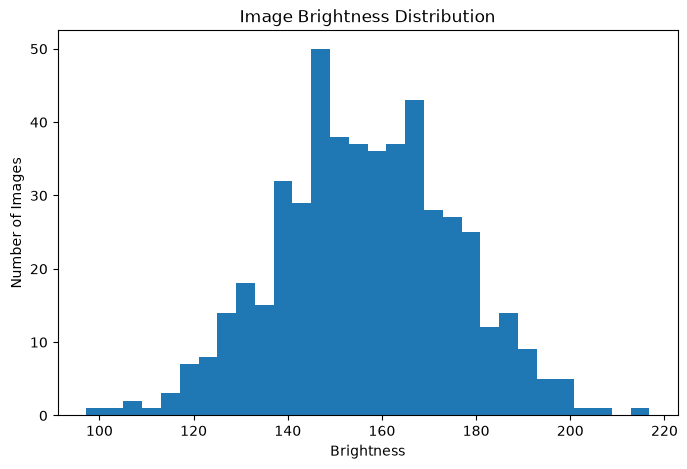

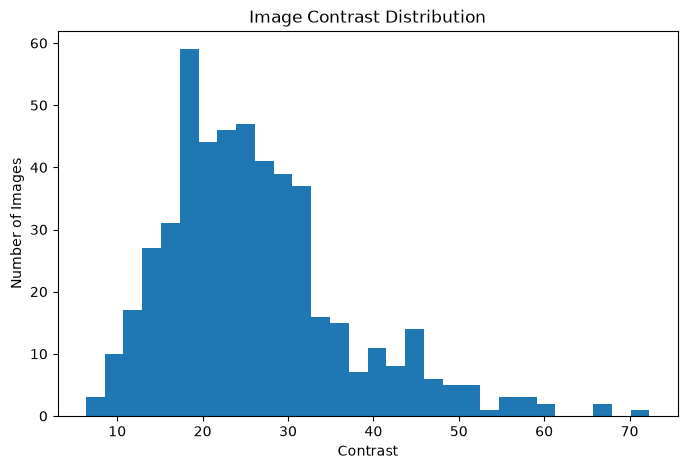

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(quality_df["blur_score"], bins=30)
plt.xlabel("Blur Score")
plt.ylabel("Number of Images")
plt.title("Image Blur Distribution")
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(quality_df["brightness"], bins=30)
plt.xlabel("Brightness")
plt.ylabel("Number of Images")
plt.title("Image Brightness Distribution")
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(quality_df["contrast"], bins=30)
plt.xlabel("Contrast")
plt.ylabel("Number of Images")
plt.title("Image Contrast Distribution")
plt.show()

In [22]:
import os
import pandas as pd
import numpy as np
from PIL import Image

# -----------------------------
# Paths
# -----------------------------
image_dir1 = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_1"
image_dir2 = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_2"

metadata_path = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_metadata.csv"

# -----------------------------
# Load metadata
# -----------------------------
df = pd.read_csv(metadata_path)

print("Total records:", len(df))

# -----------------------------
# Image preprocessing function
# -----------------------------
IMG_SIZE = (224, 224)

def preprocess_image(image_path):
    try:
        image = Image.open(image_path)

        # Convert to RGB
        image = image.convert("RGB")

        # Resize
        image = image.resize(IMG_SIZE)

        # Convert to NumPy array
        image = np.array(image, dtype=np.float32)

        # Normalize pixel values: 0-255 → 0-1
        image = image / 255.0

        return image

    except Exception as e:
        print("Error:", image_path, e)
        return None

# -----------------------------
# Test preprocessing on 5 images
# -----------------------------
sample_images = df["image_id"].head(5)

for image_id in sample_images:

    filename = image_id + ".jpg"

    path1 = os.path.join(image_dir1, filename)
    path2 = os.path.join(image_dir2, filename)

    if os.path.exists(path1):
        image_path = path1
    elif os.path.exists(path2):
        image_path = path2
    else:
        print("Image not found:", image_id)
        continue

    processed = preprocess_image(image_path)

    if processed is not None:
        print(
            image_id,
            "→ Shape:", processed.shape,
            "Min:", processed.min(),
            "Max:", processed.max()
        )

Total records: 10015
ISIC_0027419 → Shape: (224, 224, 3) Min: 0.1882353 Max: 1.0
ISIC_0025030 → Shape: (224, 224, 3) Min: 0.043137256 Max: 1.0
ISIC_0026769 → Shape: (224, 224, 3) Min: 0.23137255 Max: 0.95686275
ISIC_0025661 → Shape: (224, 224, 3) Min: 0.02745098 Max: 0.96862745
ISIC_0031633 → Shape: (224, 224, 3) Min: 0.07058824 Max: 1.0


In [23]:
import pandas as pd

metadata_path = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_metadata.csv"

metadata = pd.read_csv(metadata_path)

data = metadata.copy()
data["label"] = data["dx"]

print("Data loaded:", len(data))
print(data[["image_id", "label"]].head())

Data loaded: 10015
       image_id label
0  ISIC_0027419   bkl
1  ISIC_0025030   bkl
2  ISIC_0026769   bkl
3  ISIC_0025661   bkl
4  ISIC_0031633   bkl


In [25]:
print(data.columns.tolist())

['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'label']


In [26]:
# ==========================================
# STEP 2: Create image paths and labels
# ==========================================

import os
import pandas as pd

# Disease class names
class_names = {
    "nv": "Melanocytic Nevus",
    "mel": "Melanoma",
    "bkl": "Benign Keratosis",
    "bcc": "Basal Cell Carcinoma",
    "akiec": "Actinic Keratosis",
    "vasc": "Vascular Lesion",
    "df": "Dermatofibroma"
}

image_paths = []
labels = []
missing_images = []

# Go through all 10,015 records
for _, row in df.iterrows():

    image_id = row["image_id"]
    label = row["dx"]
    filename = image_id + ".jpg"

    path1 = os.path.join(image_dir1, filename)
    path2 = os.path.join(image_dir2, filename)

    # Find the image
    if os.path.exists(path1):
        image_path = path1

    elif os.path.exists(path2):
        image_path = path2

    else:
        missing_images.append(image_id)
        continue

    image_paths.append(image_path)
    labels.append(label)

# Create a new DataFrame
dataset_df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

print("================================")
print("DATASET PREPARATION COMPLETED")
print("================================")

print("Total images found:", len(dataset_df))
print("Missing images:", len(missing_images))

print("\nDisease distribution:")
print(dataset_df["label"].value_counts())

print("\nFirst 5 records:")
print(dataset_df.head())

DATASET PREPARATION COMPLETED
Total images found: 10015
Missing images: 0

Disease distribution:
label
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

First 5 records:
                                          image_path label
0  C:\Users\muvva\Downloads\DermaVision\HAM10000_...   bkl
1  C:\Users\muvva\Downloads\DermaVision\HAM10000_...   bkl
2  C:\Users\muvva\Downloads\DermaVision\HAM10000_...   bkl
3  C:\Users\muvva\Downloads\DermaVision\HAM10000_...   bkl
4  C:\Users\muvva\Downloads\DermaVision\HAM10000_...   bkl


Original shape: (450, 600, 3)
Processed shape: (224, 224, 3)
Minimum pixel value: 0.06274509803921569
Maximum pixel value: 0.9686274509803922


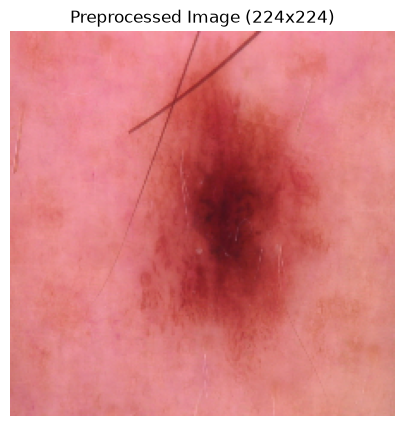

In [28]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the first image directly from our dataset folder
sample_path = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_1\ISIC_0024306.jpg"

# Read image
image = cv2.imread(sample_path)

# Check image
if image is None:
    print("Image could not be loaded!")
else:
    # Convert BGR to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize to 224 x 224
    resized_image = cv2.resize(image, (224, 224))

    # Normalize pixels to 0-1
    normalized_image = resized_image / 255.0

    print("Original shape:", image.shape)
    print("Processed shape:", normalized_image.shape)
    print("Minimum pixel value:", normalized_image.min())
    print("Maximum pixel value:", normalized_image.max())

    # Display
    plt.figure(figsize=(5, 5))
    plt.imshow(normalized_image)
    plt.title("Preprocessed Image (224x224)")
    plt.axis("off")
    plt.show()

In [27]:
import os

# Copy original metadata
data = df.copy()

# Base folders
image_dir1 = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_1"
image_dir2 = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_2"

# Function to find the image
def find_image_path(image_id):
    filename = image_id + ".jpg"

    path1 = os.path.join(image_dir1, filename)
    path2 = os.path.join(image_dir2, filename)

    if os.path.exists(path1):
        return path1
    elif os.path.exists(path2):
        return path2
    else:
        return None

# Create image paths
data["image_path"] = data["image_id"].apply(find_image_path)

# Rename disease column
data["label"] = data["dx"]

# Keep only required columns
data = data[["image_id", "image_path", "label"]]

print("Total records:", len(data))
print("Missing images:", data["image_path"].isna().sum())

print("\nFirst 5 records:")
print(data.head())

Total records: 10015
Missing images: 0

First 5 records:
       image_id                                         image_path label
0  ISIC_0027419  C:\Users\muvva\Downloads\DermaVision\HAM10000_...   bkl
1  ISIC_0025030  C:\Users\muvva\Downloads\DermaVision\HAM10000_...   bkl
2  ISIC_0026769  C:\Users\muvva\Downloads\DermaVision\HAM10000_...   bkl
3  ISIC_0025661  C:\Users\muvva\Downloads\DermaVision\HAM10000_...   bkl
4  ISIC_0031633  C:\Users\muvva\Downloads\DermaVision\HAM10000_...   bkl


In [28]:
import pandas as pd

metadata_path = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_metadata.csv"

metadata = pd.read_csv(metadata_path)

data = metadata.copy()
data["label"] = data["dx"]

print("Data loaded:", len(data))
print(data[["image_id", "label"]].head())

Data loaded: 10015
       image_id label
0  ISIC_0027419   bkl
1  ISIC_0025030   bkl
2  ISIC_0026769   bkl
3  ISIC_0025661   bkl
4  ISIC_0031633   bkl


In [29]:
from sklearn.model_selection import train_test_split

# 80% training, 20% temporary
train_df, temp_df = train_test_split(
    data,
    test_size=0.20,
    stratify=data["label"],
    random_state=42
)

# Split the remaining 20% equally:
# 10% validation and 10% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("DATASET SPLIT COMPLETED")
print("------------------------")
print("Training images   :", len(train_df))
print("Validation images :", len(val_df))
print("Testing images    :", len(test_df))
print("Total images      :", len(train_df) + len(val_df) + len(test_df))

DATASET SPLIT COMPLETED
------------------------
Training images   : 8012
Validation images : 1001
Testing images    : 1002
Total images      : 10015


In [31]:
print("TRAINING DISTRIBUTION")
print(train_df["label"].value_counts())

print("\nVALIDATION DISTRIBUTION")
print(val_df["label"].value_counts())

print("\nTESTING DISTRIBUTION")
print(test_df["label"].value_counts())

TRAINING DISTRIBUTION
label
nv       5364
mel       890
bkl       879
bcc       411
akiec     262
vasc      114
df         92
Name: count, dtype: int64

VALIDATION DISTRIBUTION
label
nv       670
mel      111
bkl      110
bcc       51
akiec     33
vasc      14
df        12
Name: count, dtype: int64

TESTING DISTRIBUTION
label
nv       671
mel      112
bkl      110
bcc       52
akiec     32
vasc      14
df        11
Name: count, dtype: int64


In [34]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
    tf.keras.layers.RandomContrast(0.10)
], name="data_augmentation")

print("Data augmentation pipeline created successfully!")

Data augmentation pipeline created successfully!


In [33]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [35]:
print([name for name in globals() if "train" in name.lower()])

['train_test_split', 'train_df']


In [37]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Create a function to load and preprocess one image
def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

print("Image loading function created successfully!")

Image loading function created successfully!


Image ID: ISIC_0033319
Disease: nv
Image path: C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_2\ISIC_0033319.jpg


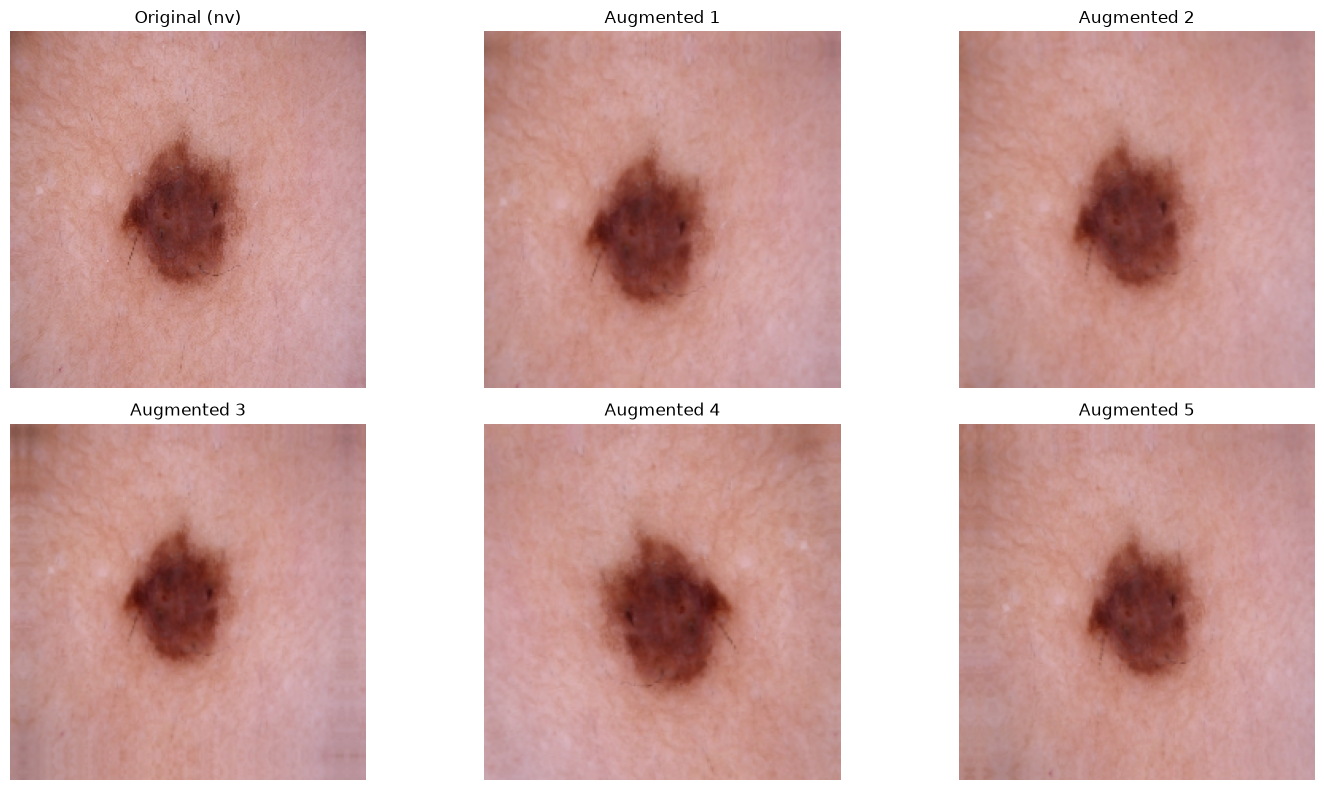

In [38]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os

# Image folders
image_dir1 = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_1"
image_dir2 = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_2"

# Take one image from training data
image_id = train_df.iloc[0]["image_id"]
label = train_df.iloc[0]["label"]

# Find the image
path1 = os.path.join(image_dir1, image_id + ".jpg")
path2 = os.path.join(image_dir2, image_id + ".jpg")

if os.path.exists(path1):
    image_path = path1
else:
    image_path = path2

print("Image ID:", image_id)
print("Disease:", label)
print("Image path:", image_path)

# Load image
image = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

# Convert to array
image = tf.keras.utils.img_to_array(image)

# Add batch dimension
image = tf.expand_dims(image, axis=0)

# Generate augmented images
augmented_images = [
    data_augmentation(image, training=True)[0]
    for _ in range(5)
]

# Display original + augmented images
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(image[0].numpy().astype("uint8"))
plt.title(f"Original ({label})")
plt.axis("off")

for i, aug_image in enumerate(augmented_images):
    plt.subplot(2, 3, i + 2)
    plt.imshow(
        tf.clip_by_value(aug_image, 0, 255).numpy().astype("uint8")
    )
    plt.title(f"Augmented {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [60]:
import os

image_dir1 = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_1"
image_dir2 = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_2"

def find_image_path(image_id):
    path1 = os.path.join(image_dir1, image_id + ".jpg")
    path2 = os.path.join(image_dir2, image_id + ".jpg")

    if os.path.exists(path1):
        return path1
    elif os.path.exists(path2):
        return path2
    else:
        return None

train_df["image_path"] = train_df["image_id"].apply(find_image_path)
val_df["image_path"] = val_df["image_id"].apply(find_image_path)
test_df["image_path"] = test_df["image_id"].apply(find_image_path)

print("Training missing:", train_df["image_path"].isna().sum())
print("Validation missing:", val_df["image_path"].isna().sum())
print("Testing missing:", test_df["image_path"].isna().sum())

Training missing: 0
Validation missing: 0
Testing missing: 0


In [40]:
from sklearn.preprocessing import LabelEncoder

# Create label encoder
label_encoder = LabelEncoder()

# Fit using all disease classes
label_encoder.fit(data["label"])

# Convert labels to numbers
train_df["label_encoded"] = label_encoder.transform(train_df["label"])
val_df["label_encoded"] = label_encoder.transform(val_df["label"])
test_df["label_encoded"] = label_encoder.transform(test_df["label"])

print("Disease classes:")
for i, class_name in enumerate(label_encoder.classes_):
    print(i, "->", class_name)

print("\nLabel encoding completed!")

Disease classes:
0 -> akiec
1 -> bcc
2 -> bkl
3 -> df
4 -> mel
5 -> nv
6 -> vasc

Label encoding completed!


In [41]:
# Create TensorFlow datasets

train_paths = train_df["image_path"].values
train_labels = train_df["label_encoded"].values

val_paths = val_df["image_path"].values
val_labels = val_df["label_encoded"].values

test_paths = test_df["image_path"].values
test_labels = test_df["label_encoded"].values


# Training dataset
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

# Validation dataset
val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

# Testing dataset
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)


# Apply image loading and preprocessing
train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [42]:
BATCH_SIZE = 32

# Batch the datasets
train_ds = train_ds.batch(BATCH_SIZE)
val_ds = val_ds.batch(BATCH_SIZE)
test_ds = test_ds.batch(BATCH_SIZE)

print("Datasets batched successfully!")

Datasets batched successfully!


In [43]:
# Create TensorFlow datasets again

train_paths = train_df["image_path"].values
train_labels = train_df["label_encoded"].values

val_paths = val_df["image_path"].values
val_labels = val_df["label_encoded"].values

test_paths = test_df["image_path"].values
test_labels = test_df["label_encoded"].values

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

print("TensorFlow datasets recreated successfully!")

TensorFlow datasets recreated successfully!


In [44]:
BATCH_SIZE = 32

train_ds = train_ds.batch(BATCH_SIZE)
val_ds = val_ds.batch(BATCH_SIZE)
test_ds = test_ds.batch(BATCH_SIZE)

print("Datasets batched successfully!")

Datasets batched successfully!


In [45]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Load metadata
metadata_path = r"C:\Users\muvva\Downloads\DermaVision\HAM10000_metadata.csv"

metadata = pd.read_csv(metadata_path)

# Create data
data = metadata.copy()
data["label"] = data["dx"]

print("Total records:", len(data))

# Encode disease labels
label_encoder = LabelEncoder()
data["label_encoded"] = label_encoder.fit_transform(data["label"])

# Split: 80% training, 20% temporary
train_df, temp_df = train_test_split(
    data,
    test_size=0.20,
    stratify=data["label"],
    random_state=42
)

# Split remaining 20% into 10% validation and 10% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("DATASET SPLIT RESTORED")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Total records: 10015
DATASET SPLIT RESTORED
Training: 8012
Validation: 1001
Testing: 1002


In [46]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Get training labels
y_train = train_df["label_encoded"].values

# Get all class numbers
classes = np.unique(y_train)

# Calculate balanced class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

# Convert to dictionary
class_weights = dict(zip(classes, weights))

print("Class weights:")

for class_number, weight in class_weights.items():
    class_name = label_encoder.inverse_transform([class_number])[0]
    print(f"{class_number} -> {class_name}: {weight:.4f}")

Class weights:
0 -> akiec: 4.3686
1 -> bcc: 2.7848
2 -> bkl: 1.3021
3 -> df: 12.4410
4 -> mel: 1.2860
5 -> nv: 0.2134
6 -> vasc: 10.0401


In [47]:
import tensorflow as tf

# Number of disease classes
num_classes = len(label_encoder.classes_)

# Load pretrained EfficientNetV2B0
base_model = tf.keras.applications.EfficientNetV2B0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers initially
base_model.trainable = False

print("EfficientNetV2B0 loaded successfully!")
print("Number of classes:", num_classes)

EfficientNetV2B0 loaded successfully!
Number of classes: 7


In [48]:
import tensorflow as tf
from tensorflow.keras import layers

class HybridAttention(layers.Layer):
    def __init__(self, reduction_ratio=8, **kwargs):
        super().__init__(**kwargs)
        self.reduction_ratio = reduction_ratio

    def build(self, input_shape):
        channels = input_shape[-1]

        # Channel attention
        self.channel_dense1 = layers.Dense(
            channels // self.reduction_ratio,
            activation="relu"
        )
        self.channel_dense2 = layers.Dense(
            channels,
            activation="sigmoid"
        )

        # Spatial attention
        self.spatial_conv = layers.Conv2D(
            1,
            kernel_size=7,
            padding="same",
            activation="sigmoid"
        )

        super().build(input_shape)

    def call(self, inputs):
        # -------- Channel Attention --------
        avg_pool = tf.reduce_mean(
            inputs, axis=[1, 2], keepdims=True
        )

        channel_attention = self.channel_dense1(avg_pool)
        channel_attention = self.channel_dense2(channel_attention)

        channel_refined = inputs * channel_attention

        # -------- Spatial Attention --------
        avg_spatial = tf.reduce_mean(
            channel_refined, axis=-1, keepdims=True
        )

        max_spatial = tf.reduce_max(
            channel_refined, axis=-1, keepdims=True
        )

        spatial_features = tf.concat(
            [avg_spatial, max_spatial],
            axis=-1
        )

        spatial_attention = self.spatial_conv(spatial_features)

        output = channel_refined * spatial_attention

        return output


print("Hybrid Attention created successfully!")

Hybrid Attention created successfully!


In [3]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nModel file exists:")
print(os.path.exists("dermavision_best_model.keras"))

print("\nModel file in current directory:")
print(os.path.exists("dermavision_best_model.keras"))

Current working directory:
c:\Users\muvva\Downloads\DermaVision\notebooks

Model file exists:
True

Model file in current directory:
True


In [7]:

import tensorflow as tf
from tensorflow.keras import layers

# 1. Define Hybrid Attention
class HybridAttention(layers.Layer):
    def __init__(self, reduction_ratio=8, **kwargs):
        super().__init__(**kwargs)
        self.reduction_ratio = reduction_ratio

    def build(self, input_shape):
        channels = int(input_shape[-1])
        reduced_channels = max(1, channels // self.reduction_ratio)

        # Channel attention
        self.channel_dense1 = layers.Dense(
            reduced_channels,
            activation="relu"
        )
        self.channel_dense2 = layers.Dense(
            channels,
            activation="sigmoid"
        )

        # Spatial attention
        self.spatial_conv = layers.Conv2D(
            filters=1,
            kernel_size=7,
            padding="same",
            activation="sigmoid"
        )

        super().build(input_shape)

    def call(self, inputs):
        # Channel attention
        avg_pool = tf.reduce_mean(
            inputs, axis=[1, 2], keepdims=True
        )
        channel_attention = self.channel_dense1(avg_pool)
        channel_attention = self.channel_dense2(channel_attention)
        channel_refined = inputs * channel_attention

        # Spatial attention
        avg_spatial = tf.reduce_mean(
            channel_refined, axis=-1, keepdims=True
        )
        max_spatial = tf.reduce_max(
            channel_refined, axis=-1, keepdims=True
        )
        spatial_features = tf.concat(
            [avg_spatial, max_spatial], axis=-1
        )
        spatial_attention = self.spatial_conv(spatial_features)

        return channel_refined * spatial_attention

    def get_config(self):
        config = super().get_config()
        config.update({
            "reduction_ratio": self.reduction_ratio
        })
        return config


print("Hybrid Attention class defined successfully!")

# 2. Load the existing saved model
model_path = "dermavision_best_model.keras"

model = tf.keras.models.load_model(
    model_path,
    custom_objects={"HybridAttention": HybridAttention},
    compile=False
)

print("\nModel loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total parameters:", model.count_params())


Hybrid Attention class defined successfully!


Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 7)
Total parameters: 6339418


In [5]:
print("Model input:", model.input_shape)
print("Model output:", model.output_shape)

print("\nProject class mapping:")

Model input: (None, 224, 224, 3)
Model output: (None, 7)

Project class mapping:


In [6]:
from pathlib import Path

print(Path("../config.py").read_text(encoding="utf-8"))

"""
DermaVision: Skin Cancer Detection Using EfficientNetV2 with Hybrid Attention and Ensemble Learning
Configuration Module
"""

import os
from pathlib import Path

# ---------------------------------------------------------------------------
# Base Directories
# ---------------------------------------------------------------------------
BASE_DIR = Path(__file__).resolve().parent

# Check if dataset is in root folder (e.g. Downloads/DermaVision) or in data/raw
if (BASE_DIR / "HAM10000_metadata.csv").is_file():
    RAW_DATA_DIR = BASE_DIR
    METADATA_PATH = BASE_DIR / "HAM10000_metadata.csv"
    RAW_PART1_DIR = BASE_DIR / "HAM10000_images_part_1"
    RAW_PART2_DIR = BASE_DIR / "HAM10000_images_part_2"
else:
    RAW_DATA_DIR = BASE_DIR / "data" / "raw"
    METADATA_PATH = RAW_DATA_DIR / "HAM10000_metadata.csv"
    RAW_PART1_DIR = RAW_DATA_DIR / "HAM10000_images_part_1"
    RAW_PART2_DIR = RAW_DATA_DIR / "HAM10000_images_part_2"

DATA_DIR = BASE_DIR / "data"
PROCESSED_DATA_DIR = DATA_DI

In [7]:
from pathlib import Path

config_text = Path("../config.py").read_text(encoding="utf-8")

for i, line in enumerate(config_text.splitlines(), start=1):
    if any(word in line.lower() for word in [
        "class_names", "class_labels", "class_to_id",
        "classes", "label_map"
    ]):
        print(f"{i}: {line}")

42: CLASS_NAMES = [
52: CLASS_LABELS = {
62: NUM_CLASSES = len(CLASS_NAMES)
63: LABEL_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
64: IDX_TO_LABEL = {idx: name for idx, name in enumerate(CLASS_NAMES)}


In [8]:
from pathlib import Path

config_text = Path("../config.py").read_text(encoding="utf-8")
lines = config_text.splitlines()

# Print the class names and label mapping definitions
for start, end in [(40, 66)]:
    print("\n".join(
        f"{i+1}: {lines[i]}"
        for i in range(start-1, min(end, len(lines)))
    ))

40: # ---------------------------------------------------------------------------
41: # 7 skin lesion diagnostic categories
42: CLASS_NAMES = [
43:     "akiec",  # Actinic keratoses and intraepithelial carcinoma
44:     "bcc",    # Basal cell carcinoma
45:     "bkl",    # Benign keratosis-like lesions
46:     "df",     # Dermatofibroma
47:     "mel",    # Melanoma
48:     "nv",     # Melanocytic nevi
49:     "vasc"    # Vascular lesions
50: ]
51: 
52: CLASS_LABELS = {
53:     "akiec": "Actinic Keratoses / Intraepithelial Carcinoma",
54:     "bcc": "Basal Cell Carcinoma",
55:     "bkl": "Benign Keratosis-like Lesions",
56:     "df": "Dermatofibroma",
57:     "mel": "Melanoma",
58:     "nv": "Melanocytic Nevi",
59:     "vasc": "Vascular Lesions"
60: }
61: 
62: NUM_CLASSES = len(CLASS_NAMES)
63: LABEL_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
64: IDX_TO_LABEL = {idx: name for idx, name in enumerate(CLASS_NAMES)}
65: 
66: # -----------------------------------------------

In [9]:
print("Model layers:")
for i, layer in enumerate(model.layers):
    print(i, layer.name, layer.__class__.__name__)

Model layers:
0 input_layer_2 InputLayer
1 efficientnetv2-b0 Functional
2 hybrid_attention HybridAttention
3 global_average_pooling2d GlobalAveragePooling2D
4 dropout Dropout
5 dense_2 Dense


In [10]:
from pathlib import Path

project_root = Path("..").resolve()

paths_to_check = [
    project_root / "HAM10000_metadata.csv",
    project_root / "HAM10000_images_part_1",
    project_root / "HAM10000_images_part_2",
]

for path in paths_to_check:
    print(path.name, "->", path.exists())

HAM10000_metadata.csv -> True
HAM10000_images_part_1 -> True
HAM10000_images_part_2 -> True


In [11]:
from pathlib import Path

root = Path("..").resolve()

print("Possible split files:")
for path in root.rglob("*"):
    if path.is_file() and any(
        word in path.name.lower()
        for word in ["test", "split", "train_df", "val_df"]
    ):
        if path.suffix.lower() in [".csv", ".json", ".pkl", ".pickle"]:
            print(path.relative_to(root))

Possible split files:
data\processed\test.csv
venv\Lib\site-packages\numpy\random\tests\data\mt19937-testset-1.csv
venv\Lib\site-packages\numpy\random\tests\data\mt19937-testset-2.csv
venv\Lib\site-packages\numpy\random\tests\data\pcg64-testset-1.csv
venv\Lib\site-packages\numpy\random\tests\data\pcg64-testset-2.csv
venv\Lib\site-packages\numpy\random\tests\data\pcg64dxsm-testset-1.csv
venv\Lib\site-packages\numpy\random\tests\data\pcg64dxsm-testset-2.csv
venv\Lib\site-packages\numpy\random\tests\data\philox-testset-1.csv
venv\Lib\site-packages\numpy\random\tests\data\philox-testset-2.csv
venv\Lib\site-packages\numpy\random\tests\data\sfc64-testset-1.csv
venv\Lib\site-packages\numpy\random\tests\data\sfc64-testset-2.csv


In [12]:
import pandas as pd
from pathlib import Path

test_path = Path("../data/processed/test.csv")

test_df = pd.read_csv(test_path)

print("Test dataset shape:", test_df.shape)
print("\nColumn names:")
print(test_df.columns.tolist())

print("\nFirst 5 rows:")
display(test_df.head())

Test dataset shape: (1497, 9)

Column names:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'image_path', 'target']

First 5 rows:


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,target
0,HAM_0001601,ISIC_0025915,bkl,histo,75.0,male,upper extremity,C:\Users\muvva\Downloads\DermaVision\HAM10000_...,2
1,HAM_0001601,ISIC_0031029,bkl,histo,75.0,male,upper extremity,C:\Users\muvva\Downloads\DermaVision\HAM10000_...,2
2,HAM_0007571,ISIC_0029836,bkl,histo,70.0,male,chest,C:\Users\muvva\Downloads\DermaVision\HAM10000_...,2
3,HAM_0007571,ISIC_0032129,bkl,histo,70.0,male,chest,C:\Users\muvva\Downloads\DermaVision\HAM10000_...,2
4,HAM_0007409,ISIC_0025076,bkl,histo,50.0,male,upper extremity,C:\Users\muvva\Downloads\DermaVision\HAM10000_...,2


In [13]:
import os

print("Test rows:", len(test_df))
print("Missing image paths:", test_df["image_path"].isna().sum())
print("Existing image files:", test_df["image_path"].apply(
    lambda p: os.path.isfile(p) if isinstance(p, str) else False
).sum())

print("\nTarget label distribution:")
print(test_df["target"].value_counts().sort_index())

print("\nUnique target labels:")
print(sorted(test_df["target"].dropna().unique()))

Test rows: 1497
Missing image paths: 0
Existing image files: 1497

Target label distribution:
target
0      51
1      77
2     157
3      22
4     168
5    1000
6      22
Name: count, dtype: int64

Unique target labels:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [14]:
print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)

print("\nFirst layers:")
for layer in model.layers[:4]:
    print(layer.name, "-", layer.__class__.__name__)

print("\nFirst test image:")
print(test_df["image_path"].iloc[0])
print("True class:", test_df["target"].iloc[0])

Model input shape: (None, 224, 224, 3)
Model output shape: (None, 7)

First layers:
input_layer_2 - InputLayer
efficientnetv2-b0 - Functional
hybrid_attention - HybridAttention
global_average_pooling2d - GlobalAveragePooling2D

First test image:
C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_1\ISIC_0025915.jpg
True class: 2


In [15]:
print("Model preprocessing-related layers:")

for layer in model.layers:
    print(layer.name, type(layer).__name__)

Model preprocessing-related layers:
input_layer_2 InputLayer
efficientnetv2-b0 Functional
hybrid_attention HybridAttention
global_average_pooling2d GlobalAveragePooling2D
dropout Dropout
dense_2 Dense


In [77]:
#Combining efficientNetV2 + Hybrid attention
# Build DermaVision model

inputs = tf.keras.Input(shape=(224, 224, 3))

# EfficientNetV2 feature extraction
x = base_model(inputs, training=False)

print("Feature map shape:", x.shape)

# Hybrid Attention
x = HybridAttention()(x)

# Convert feature maps into one feature vector
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# Dropout to reduce overfitting
x = tf.keras.layers.Dropout(0.3)(x)

# Final classification layer
outputs = tf.keras.layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="DermaVision_EfficientNetV2_HybridAttention"
)

model.summary()

Feature map shape: (None, 7, 7, 1280)


Model: "DermaVision_EfficientNetV2_HybridAttention"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hybrid_attention_1              │ (None, 7, 7, 1280)     │       411,139 │
│ (HybridAttention)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,339,418 (24.18 MB)

 Trainable params: 420,106 (1.60 MB)

 Non-trainable params: 5,919,312 (22.58 MB)

In [16]:
backbone = model.get_layer("efficientnetv2-b0")

print("Backbone name:", backbone.name)
print("Backbone input shape:", backbone.input_shape)
print("Backbone input dtype:", backbone.input.dtype)

print("\nFirst backbone layers:")
for layer in backbone.layers[:12]:
    print(layer.name, "-", layer.__class__.__name__)

Backbone name: efficientnetv2-b0
Backbone input shape: (None, 224, 224, 3)
Backbone input dtype: float32

First backbone layers:
input_layer_1 - InputLayer
rescaling - Rescaling
normalization - Normalization
stem_conv - Conv2D
stem_bn - BatchNormalization
stem_activation - Activation
block1a_project_conv - Conv2D
block1a_project_bn - BatchNormalization
block1a_project_activation - Activation
block2a_expand_conv - Conv2D
block2a_expand_bn - BatchNormalization
block2a_expand_activation - Activation


Test accuracy: 5.14 %

Classification report:
              precision    recall  f1-score   support

       akiec       0.14      0.02      0.03        51
         bcc       0.04      0.43      0.08        77
         bkl       0.11      0.08      0.09       157
          df       0.02      0.32      0.03        22
         mel       0.10      0.07      0.08       168
          nv       0.82      0.01      0.02      1000
        vasc       0.03      0.14      0.06        22

    accuracy                           0.05      1497
   macro avg       0.18      0.15      0.06      1497
weighted avg       0.58      0.05      0.04      1497



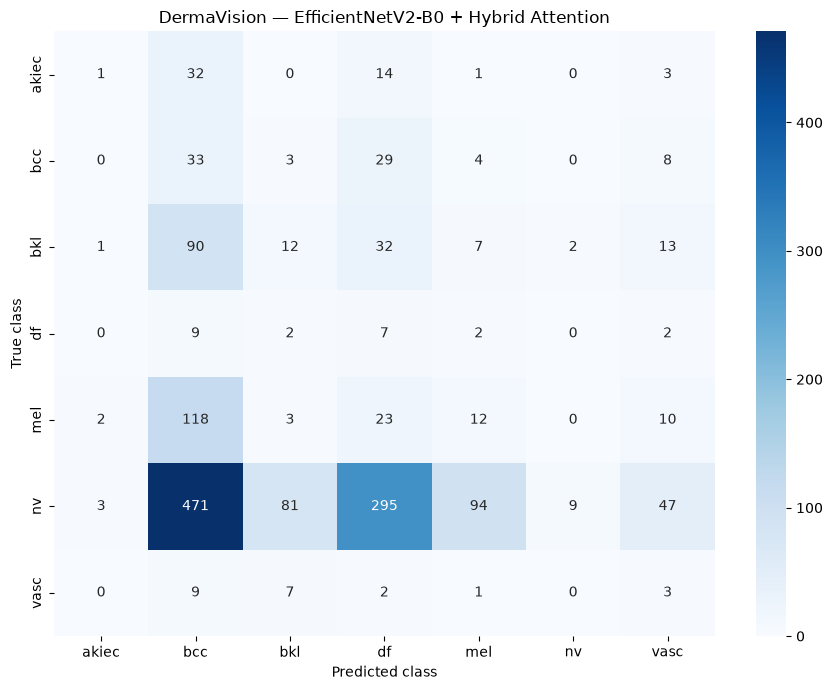

In [8]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Load and resize each image to 224x224 RGB.
def load_test_image(path):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image = tf.image.resize(image, (224, 224))
    return image  # Keep pixel values in 0–255; model preprocesses internally.

test_paths = test_df["image_path"].astype(str).tolist()
y_true = test_df["target"].astype(int).to_numpy()

# Predict in batches to limit memory use.
predictions = []
for start in range(0, len(test_paths), 16):
    batch_paths = test_paths[start:start + 16]
    images = tf.stack([load_test_image(p) for p in batch_paths])
    batch_predictions = model.predict(images, verbose=0)
    predictions.extend(batch_predictions)

y_pred = np.argmax(np.asarray(predictions), axis=1)

print("Test accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("DermaVision — EfficientNetV2-B0 + Hybrid Attention")
plt.tight_layout()
plt.show()


In [9]:
backbone = model.get_layer("efficientnetv2-b0")

for layer in backbone.layers[:3]:
    if layer.name == "rescaling":
        print("Rescaling config:", layer.get_config())
    elif layer.name == "normalization":
        config = layer.get_config()
        print("Normalization mean:", config.get("mean"))
        print("Normalization variance:", config.get("variance"))

Rescaling config: {'name': 'rescaling', 'trainable': False, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'scale': 0.00392156862745098, 'offset': 0.0}
Normalization mean: [0.485, 0.456, 0.406]
Normalization variance: [0.052441, 0.050176000000000005, 0.050625]


In [10]:
print("Target label mapping from test.csv:")

print(
    test_df[["dx", "target"]]
    .drop_duplicates()
    .sort_values("target")
    .to_string(index=False)
)

Target label mapping from test.csv:
   dx  target
akiec       0
  bcc       1
  bkl       2
   df       3
  mel       4
   nv       5
 vasc       6


In [5]:
import pandas as pd
from pathlib import Path

test_path = Path("../data/processed/test.csv")
test_df = pd.read_csv(test_path)

print("Test dataset loaded:", test_df.shape)
print("Image paths:", test_df["image_path"].notna().sum())
print("Target labels:", sorted(test_df["target"].unique()))

Test dataset loaded: (1497, 9)
Image paths: 1497
Target labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [11]:
import numpy as np
import tensorflow as tf

image_path = test_df["image_path"].iloc[0]
true_label = int(test_df["target"].iloc[0])

image = tf.io.read_file(image_path)
image = tf.io.decode_image(image, channels=3, expand_animations=False)
image = tf.image.resize(image, (224, 224))
image = tf.expand_dims(image, axis=0)

probabilities = model.predict(image, verbose=0)[0]
predicted_label = int(np.argmax(probabilities))

print("True class:", CLASS_NAMES[true_label])
print("Predicted class:", CLASS_NAMES[predicted_label])
print("Maximum probability:", round(float(np.max(probabilities)), 4))
print("All probabilities:", np.round(probabilities, 4))

True class: bkl
Predicted class: mel
Maximum probability: 0.1668
All probabilities: [0.1242 0.1587 0.1263 0.1522 0.1668 0.1336 0.1381]


In [12]:
import numpy as np
import tensorflow as tf

sample_paths = test_df["image_path"].iloc[:20].tolist()
images = []

for path in sample_paths:
    img = tf.io.read_file(path)
    img = tf.io.decode_image(
        img, channels=3, expand_animations=False
    )
    img = tf.image.resize(img, (224, 224))
    images.append(img)

batch = tf.stack(images)
probs = model.predict(batch, verbose=0)

print("Mean probability per class:")
print(np.round(probs.mean(axis=0), 4))

print("\nPrediction counts:")
print(np.bincount(np.argmax(probs, axis=1), minlength=7))

print("\nMean maximum probability:")
print(round(float(np.max(probs, axis=1).mean()), 4))

Mean probability per class:
[0.1325 0.1547 0.1483 0.1477 0.1502 0.1296 0.1371]

Prediction counts:
[0 6 4 5 5 0 0]

Mean maximum probability:
0.1638


In [13]:
print("Final layer:", model.layers[-1].name)
print("Final layer type:", type(model.layers[-1]).__name__)
print("Final layer config:", model.layers[-1].get_config())

Final layer: dense_2
Final layer type: Dense
Final layer config: {'name': 'dense_2', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'units': 7, 'activation': 'softmax', 'use_bias': True, 'kernel_initializer': {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None, 'input_axes': None, 'output_axes': None}, 'registered_name': None}, 'bias_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'kernel_regularizer': None, 'bias_regularizer': None, 'kernel_constraint': None, 'bias_constraint': None, 'quantization_config': None}


In [14]:
import numpy as np

print("Checking trained weights...")

for layer in model.layers:
    weights = layer.get_weights()

    if weights:
        print(f"\nLayer: {layer.name}")
        for i, weight in enumerate(weights):
            print(
                f"  Weight {i}: shape={weight.shape}, "
                f"mean={np.mean(weight):.6f}, "
                f"std={np.std(weight):.6f}"
            )

Checking trained weights...

Layer: efficientnetv2-b0
  Weight 0: shape=(3, 3, 3, 32), mean=-0.005388, std=0.764886
  Weight 1: shape=(32,), mean=5.710139, std=3.786359
  Weight 2: shape=(32,), mean=-2.617855, std=8.845386
  Weight 3: shape=(32,), mean=-0.004847, std=0.313506
  Weight 4: shape=(32,), mean=10.629196, std=6.815270
  Weight 5: shape=(3, 3, 32, 16), mean=0.000091, std=0.325054
  Weight 6: shape=(16,), mean=7.811753, std=3.275718
  Weight 7: shape=(16,), mean=2.310262, std=3.410069
  Weight 8: shape=(16,), mean=-9.641100, std=18.044081
  Weight 9: shape=(16,), mean=343.202118, std=162.257797
  Weight 10: shape=(3, 3, 16, 64), mean=-0.009064, std=0.214730
  Weight 11: shape=(64,), mean=6.145434, std=2.002735
  Weight 12: shape=(64,), mean=0.682672, std=3.323302
  Weight 13: shape=(64,), mean=-1.957823, std=18.305912
  Weight 14: shape=(64,), mean=332.249664, std=157.544632
  Weight 15: shape=(1, 1, 64, 32), mean=0.007235, std=0.356386
  Weight 16: shape=(32,), mean=5.675506,

In [15]:
import numpy as np

final_weights = model.layers[-1].get_weights()

print("Final layer kernel shape:", final_weights[0].shape)
print("Final layer bias shape:", final_weights[1].shape)

print("\nFinal layer bias values:")
print(np.round(final_weights[1], 4))

print("\nFinal layer kernel standard deviation:")
print(round(float(np.std(final_weights[0])), 6))

Final layer kernel shape: (1280, 7)
Final layer bias shape: (7,)

Final layer bias values:
[-0.0007 -0.0002 -0.0009 -0.0011  0.0015 -0.0014  0.0009]

Final layer kernel standard deviation:
0.039352


In [16]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Model file exists:", __import__("os").path.exists(
    "dermavision_best_model.keras"
))

TensorFlow version: 2.21.0
Model file exists: True


In [17]:

import numpy as np
from PIL import Image

# Load one image from your test dataset
row = test_df.iloc[0]
image_path = row["image_path"]
true_label = int(row["target"])

# Open and resize the image to the model's input size
img = Image.open(image_path).convert("RGB").resize((224, 224))
img_array = np.array(img, dtype=np.float32)

# Predict using the saved model
predictions = model.predict(np.expand_dims(img_array, axis=0), verbose=0)

predicted_class = int(np.argmax(predictions[0]))

class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

print("Image path:", image_path)
print("Actual class:", class_names[true_label])
print("Predicted class:", class_names[predicted_class])
print("Class probabilities:", np.round(predictions[0] * 100, 2))
print("Probability total:", round(float(np.sum(predictions[0])), 4))


Image path: C:\Users\muvva\Downloads\DermaVision\HAM10000_images_part_1\ISIC_0025915.jpg
Actual class: bkl
Predicted class: mel
Class probabilities: [12.61 16.03 12.9  15.05 16.04 13.2  14.18]
Probability total: 1.0


In [18]:

# Check the preprocessing layers inside the saved model

for layer in model.layers:
    if isinstance(layer, tf.keras.layers.Rescaling):
        print("Rescaling layer:", layer.name, layer.get_config())

    elif isinstance(layer, tf.keras.layers.Normalization):
        print("Normalization layer:", layer.name, layer.get_config())

print("\nFirst 15 model layers:")
for layer in model.layers[:15]:
    print(layer.name, "-", layer.__class__.__name__)



First 15 model layers:
input_layer_2 - InputLayer
efficientnetv2-b0 - Functional
hybrid_attention - HybridAttention
global_average_pooling2d - GlobalAveragePooling2D
dropout - Dropout
dense_2 - Dense


In [1]:
CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

In [21]:

from pathlib import Path

project_root = Path.cwd().parent

print("Project root:", project_root)
print("\nFiles inside models folder:")

for path in (project_root / "models").rglob("*.keras"):
    print(path)


Project root: c:\Users\muvva\Downloads\DermaVision

Files inside models folder:
c:\Users\muvva\Downloads\DermaVision\models\efficientnetv2_hybrid_attention.keras
c:\Users\muvva\Downloads\DermaVision\models\vit_best.keras


In [22]:

from pathlib import Path

project_root = Path.cwd().parent
model_paths = {
    "EfficientNetV2-B3": project_root / "models" / "efficientnetv2_hybrid_attention.keras",
    "ViT": project_root / "models" / "vit_best.keras",
}

for name, path in model_paths.items():
    print(f"\n{name}")
    print("File exists:", path.is_file())
    if path.is_file():
        print("Size (MB):", round(path.stat().st_size / (1024 * 1024), 2))



EfficientNetV2-B3
File exists: True
Size (MB): 62.12

ViT
File exists: True
Size (MB): 53.21


In [25]:

import tensorflow as tf
from pathlib import Path

project_root = Path.cwd().parent

efficientnet_path = project_root / "models" / "efficientnetv2_hybrid_attention.keras"
vit_path = project_root / "models" / "vit_best.keras"

# Load EfficientNetV2-B3
efficientnet_model = tf.keras.models.load_model(
    efficientnet_path,
    compile=False
)

print("EfficientNet loaded successfully")
print("Input shape:", efficientnet_model.input_shape)
print("Output shape:", efficientnet_model.output_shape)

# Load ViT
vit_model = tf.keras.models.load_model(
    vit_path,
    compile=False
)

print("\nViT loaded successfully")
print("Input shape:", vit_model.input_shape)
print("Output shape:", vit_model.output_shape)


TypeError: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {}, 'registered_name': 'Functional', 'build_config': {'input_shape': None}, 'compile_config': None}.

Exception encountered: Could not locate class 'SpatialPool'. Make sure custom classes and functions are decorated with `@keras.saving.register_keras_serializable()`. If they are already decorated, make sure they are all imported so that the decorator is run before trying to load them. Full object config: {'module': None, 'class_name': 'SpatialPool', 'config': {'name': 'spatial_avg_pool', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None, 'shared_ob

In [24]:

import tensorflow as tf
from tensorflow.keras import layers

@tf.keras.utils.register_keras_serializable()
class SpatialPool(layers.Layer):
    def __init__(self, mode="avg", **kwargs):
        super().__init__(**kwargs)
        self.mode = mode

    def call(self, inputs):
        if self.mode == "avg":
            return tf.reduce_mean(inputs, axis=-1, keepdims=True)
        return tf.reduce_max(inputs, axis=-1, keepdims=True)

    def compute_output_shape(self, input_shape):
        return (*input_shape[:-1], 1)

    def get_config(self):
        config = super().get_config()
        config.update({"mode": self.mode})
        return config


In [27]:

import tensorflow as tf
from pathlib import Path

project_root = Path.cwd().parent
efficientnet_path = (
    project_root / "models" / "efficientnetv2_hybrid_attention.keras"
)

# Register the custom layer using the package name from training
tf.keras.utils.get_custom_objects()["DermaVision>SpatialPool"] = SpatialPool
tf.keras.utils.get_custom_objects()["SpatialPool"] = SpatialPool

# Load the existing checkpoint
efficientnet_model = tf.keras.models.load_model(
    efficientnet_path,
    custom_objects={
        "SpatialPool": SpatialPool,
        "DermaVision>SpatialPool": SpatialPool,
    },
    compile=False
)

print("EfficientNet model loaded successfully!")
print("Input shape:", efficientnet_model.input_shape)
print("Output shape:", efficientnet_model.output_shape)


EfficientNet model loaded successfully!
Input shape: (None, 256, 256, 3)
Output shape: (None, 7)


In [33]:
import tensorflow as tf
from tensorflow.keras import layers

In [35]:

import sys
from pathlib import Path

project_root = Path.cwd().parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.train_vit import Patches, PatchEncoder

print("Patches class loaded:", Patches)
print("PatchEncoder class loaded:", PatchEncoder)


Patches class loaded: <class 'src.train_vit.Patches'>
PatchEncoder class loaded: <class 'src.train_vit.PatchEncoder'>


In [36]:

vit_path = project_root / "models" / "vit_best.keras"

tf.keras.utils.get_custom_objects()["DermaVision>Patches"] = Patches
tf.keras.utils.get_custom_objects()["DermaVision>PatchEncoder"] = PatchEncoder

vit_model = tf.keras.models.load_model(
    vit_path,
    custom_objects={
        "Patches": Patches,
        "PatchEncoder": PatchEncoder,
        "DermaVision>Patches": Patches,
        "DermaVision>PatchEncoder": PatchEncoder,
    },
    compile=False
)

print("ViT model loaded successfully!")
print("Input shape:", vit_model.input_shape)
print("Output shape:", vit_model.output_shape)


ViT model loaded successfully!
Input shape: (None, 256, 256, 3)
Output shape: (None, 7)


In [37]:

import numpy as np
from PIL import Image

class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

# Select one image from the existing test DataFrame
row = test_df.iloc[0]
image_path = row["image_path"]
true_label = int(row["target"])

# Resize to 256x256 RGB
image = Image.open(image_path).convert("RGB").resize((256, 256))
image_array = np.array(image, dtype=np.float32)

# Create a batch of one image
batch = np.expand_dims(image_array, axis=0)

# Predict with both models
eff_pred = efficientnet_model.predict(batch, verbose=0)[0]
vit_pred = vit_model.predict(batch, verbose=0)[0]

print("Actual class:", class_names[true_label])

print("\nEfficientNet:")
print("Predicted:", class_names[int(np.argmax(eff_pred))])
print("Probability total:", round(float(eff_pred.sum()), 4))
print("Probabilities (%):", np.round(eff_pred * 100, 2))

print("\nViT:")
print("Predicted:", class_names[int(np.argmax(vit_pred))])
print("Probability total:", round(float(vit_pred.sum()), 4))
print("Probabilities (%):", np.round(vit_pred * 100, 2))


Actual class: bkl

EfficientNet:
Predicted: akiec
Probability total: 1.0
Probabilities (%): [78.31  2.15  0.26  0.    0.58  9.69  9.  ]

ViT:
Predicted: bkl
Probability total: 1.0
Probabilities (%): [1.55e+00 5.00e-02 9.68e+01 2.40e-01 2.60e-01 9.00e-01 2.00e-01]


In [39]:

import sys
from pathlib import Path

project_root = Path.cwd().parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.preprocessing import create_tf_dataset

print("Dataset function imported successfully!")


Dataset function imported successfully!


In [40]:

from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Use the existing test dataset pipeline
test_ds = create_tf_dataset(
    test_df,
    batch_size=16,
    is_training=False,
    image_size=(256, 256)
)

# Get actual labels
y_true = test_df["target"].to_numpy()

# Predict with both models
eff_probs = efficientnet_model.predict(test_ds, verbose=1)
vit_probs = vit_model.predict(test_ds, verbose=1)

eff_pred = np.argmax(eff_probs, axis=1)
vit_pred = np.argmax(vit_probs, axis=1)

print("\nEfficientNetV2-B3 Test Accuracy:",
      round(accuracy_score(y_true, eff_pred) * 100, 2), "%")

print("\nViT Test Accuracy:",
      round(accuracy_score(y_true, vit_pred) * 100, 2), "%")

print("\nEfficientNet classification report:")
print(classification_report(
    y_true, eff_pred,
    labels=list(range(7)),
    target_names=class_names,
    zero_division=0
))

print("\nViT classification report:")
print(classification_report(
    y_true, vit_pred,
    labels=list(range(7)),
    target_names=class_names,
    zero_division=0
))


94/94 ━━━━━━━━━━━━━━━━━━━━ 50s 489ms/step
94/94 ━━━━━━━━━━━━━━━━━━━━ 11s 106ms/step

EfficientNetV2-B3 Test Accuracy: 5.14 %

ViT Test Accuracy: 10.49 %

EfficientNet classification report:
              precision    recall  f1-score   support

       akiec       0.00      0.00      0.00        51
         bcc       0.05      1.00      0.10        77
         bkl       0.00      0.00      0.00       157
          df       0.00      0.00      0.00        22
         mel       0.00      0.00      0.00       168
          nv       0.00      0.00      0.00      1000
        vasc       0.00      0.00      0.00        22

    accuracy                           0.05      1497
   macro avg       0.01      0.14      0.01      1497
weighted avg       0.00      0.05      0.01      1497


ViT classification report:
              precision    recall  f1-score   support

       akiec       0.00      0.00      0.00        51
         bcc       0.00      0.00      0.00        77
         bkl       0.1

In [41]:

# Inspect the preprocessing configuration of both loaded models

for name, current_model in [
    ("EfficientNetV2-B3", efficientnet_model),
    ("ViT", vit_model),
]:
    print(f"\n--- {name} ---")
    print("Input shape:", current_model.input_shape)

    for layer in current_model.layers[:10]:
        print(layer.name, "-", layer.__class__.__name__)



--- EfficientNetV2-B3 ---
Input shape: (None, 256, 256, 3)
input_image - InputLayer
efficientnetv2-b3 - Functional
global_average_pooling2d - GlobalAveragePooling2D
global_max_pooling2d - GlobalMaxPooling2D
reshape - Reshape
reshape_1 - Reshape
dense - Dense
dense_1 - Dense
add - Add
activation - Activation

--- ViT ---
Input shape: (None, 256, 256, 3)
input_image - InputLayer
patches - Patches
patch_encoder - PatchEncoder
norm_1_0 - LayerNormalization
mha_0 - MultiHeadAttention
add_1_0 - Add
norm_2_0 - LayerNormalization
mlp_dense_1_0 - Dense
mlp_dropout_1_0 - Dropout
mlp_dense_2_0 - Dense


In [42]:

# Search for preprocessing layers throughout the EfficientNet backbone

for layer in efficientnet_model.layers:
    print(layer.name, "-", layer.__class__.__name__)

    if isinstance(layer, tf.keras.Model):
        print("\nLayers inside:", layer.name)
        for sublayer in layer.layers[:12]:
            print("  ", sublayer.name, "-", sublayer.__class__.__name__)


input_image - InputLayer
efficientnetv2-b3 - Functional

Layers inside: efficientnetv2-b3
   input_layer_1 - InputLayer
   rescaling - Rescaling
   normalization - Normalization
   stem_conv - Conv2D
   stem_bn - BatchNormalization
   stem_activation - Activation
   block1a_project_conv - Conv2D
   block1a_project_bn - BatchNormalization
   block1a_project_activation - Activation
   block1b_project_conv - Conv2D
   block1b_project_bn - BatchNormalization
   block1b_project_activation - Activation
global_average_pooling2d - GlobalAveragePooling2D
global_max_pooling2d - GlobalMaxPooling2D
reshape - Reshape
reshape_1 - Reshape
dense - Dense
dense_1 - Dense
add - Add
activation - Activation
multiply - Multiply
spatial_avg_pool - SpatialPool
spatial_max_pool - SpatialPool
concatenate - Concatenate
conv2d - Conv2D
multiply_1 - Multiply
avg_pool - GlobalAveragePooling2D
bn_1 - BatchNormalization
top_dropout - Dropout
fc_1 - Dense
bn_2 - BatchNormalization
fc_dropout - Dropout
predictions - De

In [ ]:

backbone = efficientnet_model.get_layer("efficientnetv2-b3")

for layer in backbone.layers:
    if isinstance(layer, tf.keras.layers.Rescaling):
        print("\nRescaling configuration:")
        print(layer.get_config())

    elif isinstance(layer, tf.keras.layers.Normalization):
        print("\nNormalization configuration:")
        print(layer.get_config())



Layer: input_layer_1
Type: InputLayer

Layer: rescaling
Type: Rescaling
Config: {'name': 'rescaling', 'trainable': False, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'scale': 0.00392156862745098, 'offset': 0.0}

Layer: normalization
Type: Normalization
Config: {'name': 'normalization', 'trainable': False, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'axis': (3,), 'invert': False, 'mean': [0.485, 0.456, 0.406], 'variance': [0.052441, 0.050176000000000005, 0.050625]}


In [43]:

# Compare input ranges using one test image

image_01 = image_array / 255.0

for name, current_model in [
    ("EfficientNetV2-B3", efficientnet_model),
    ("ViT", vit_model),
]:
    print(f"\n--- {name} ---")

    pred_255 = current_model.predict(batch, verbose=0)[0]
    pred_01 = current_model.predict(
        np.expand_dims(image_01, axis=0), verbose=0
    )[0]

    print("Input 0-255 predicted class:",
          class_names[int(np.argmax(pred_255))])
    print("Input 0-255 max probability:",
          round(float(np.max(pred_255) * 100), 2), "%")

    print("Input 0-1 predicted class:",
          class_names[int(np.argmax(pred_01))])
    print("Input 0-1 max probability:",
          round(float(np.max(pred_01) * 100), 2), "%")



--- EfficientNetV2-B3 ---
Input 0-255 predicted class: akiec
Input 0-255 max probability: 78.31 %
Input 0-1 predicted class: bcc
Input 0-1 max probability: 24.27 %

--- ViT ---
Input 0-255 predicted class: bkl
Input 0-255 max probability: 96.8 %
Input 0-1 predicted class: bkl
Input 0-1 max probability: 99.45 %


In [78]:
# Compile the DermaVision model

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [66]:
# Recreate TensorFlow datasets correctly

import tensorflow as tf

BATCH_SIZE = 32

# Get paths and labels
train_paths = train_df["image_path"].values
train_labels = train_df["label_encoded"].values

val_paths = val_df["image_path"].values
val_labels = val_df["label_encoded"].values

test_paths = test_df["image_path"].values
test_labels = test_df["label_encoded"].values

# Create datasets from paths and labels
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

# IMPORTANT: Load and preprocess the images
train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Batch
train_ds = train_ds.batch(BATCH_SIZE)
val_ds = val_ds.batch(BATCH_SIZE)
test_ds = test_ds.batch(BATCH_SIZE)

# Apply augmentation ONLY to training data
def augment_batch(images, labels):
    images = data_augmentation(images, training=True)
    return images, labels

train_ds_augmented = train_ds.map(
    augment_batch,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Prefetch for better performance
train_ds_augmented = train_ds_augmented.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Training augmentation connected successfully!")

Training augmentation connected successfully!


In [62]:
for images, labels in train_ds_augmented.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Label data type:", labels.dtype)

Image shape: (32, 224, 224, 3)
Label shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int64'>


In [67]:
# Callbacks for proper training

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "dermavision_best_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

print("Training callbacks created successfully!")

Training callbacks created successfully!


In [69]:
print("Sample image range:")

for images, labels in train_ds_augmented.take(1):
    print("Minimum:", float(tf.reduce_min(images)))
    print("Maximum:", float(tf.reduce_max(images)))
    print("Mean:", float(tf.reduce_mean(images)))

print("\nModel input shape:", model.input_shape)

print("\nNumber of classes:", model.output_shape[-1])

Sample image range:
Minimum: 0.0
Maximum: 0.9822516441345215
Mean: 0.6203978657722473

Model input shape: (None, 224, 224, 3)

Number of classes: 7


In [70]:
print("EfficientNetV2 preprocessing setting:")

try:
    print(base_model.get_config().get("include_preprocessing"))
except:
    print("Could not read setting")

EfficientNetV2 preprocessing setting:
None


In [71]:
print("Base model preprocessing information:")
print("Include preprocessing:", base_model.get_config().get("include_preprocessing"))
print("Input dtype:", base_model.input.dtype)
print("Input shape:", base_model.input_shape)

print("\nFirst few layers:")
for layer in base_model.layers[:5]:
    print(layer.name, "->", layer.__class__.__name__)

Base model preprocessing information:
Include preprocessing: None
Input dtype: float32
Input shape: (None, 224, 224, 3)

First few layers:
input_layer_1 -> InputLayer
rescaling -> Rescaling
normalization -> Normalization
stem_conv -> Conv2D
stem_bn -> BatchNormalization


In [72]:
IMG_SIZE = (224, 224)

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label

print("Image loading function updated successfully!")



Image loading function updated successfully!


In [73]:
BATCH_SIZE = 32

train_paths = train_df["image_path"].values
train_labels = train_df["label_encoded"].values

val_paths = val_df["image_path"].values
val_labels = val_df["label_encoded"].values

test_paths = test_df["image_path"].values
test_labels = test_df["label_encoded"].values

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.batch(BATCH_SIZE)
val_ds = val_ds.batch(BATCH_SIZE)
test_ds = test_ds.batch(BATCH_SIZE)

print("Datasets recreated successfully!")

Datasets recreated successfully!


In [74]:
def augment_batch(images, labels):
    images = data_augmentation(images, training=True)
    return images, labels

train_ds_augmented = train_ds.map(
    augment_batch,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds_augmented = train_ds_augmented.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Training augmentation connected successfully!")

Training augmentation connected successfully!


In [76]:
for images, labels in train_ds.take(1):
    predictions = model(images, training=False)

    print("Input shape:", images.shape)
    print("Prediction shape:", predictions.shape)
    print("First prediction:", predictions[0])
    print("Prediction sum:", float(tf.reduce_sum(predictions[0])))

Input shape: (32, 224, 224, 3)
Prediction shape: (32, 7)
First prediction: tf.Tensor(
[0.13168328 0.1539112  0.13886622 0.13923255 0.15242913 0.12736614
 0.1565114 ], shape=(7,), dtype=float32)
Prediction sum: 0.9999998807907104


In [79]:
print("Early stopping:", early_stopping)
print("Reduce LR:", reduce_lr)
print("Model checkpoint:", model_checkpoint)

Early stopping: <keras.src.callbacks.early_stopping.EarlyStopping object at 0x000001D930C90150>
Reduce LR: <keras.src.callbacks.reduce_lr_on_plateau.ReduceLROnPlateau object at 0x000001D930A01950>
Model checkpoint: <keras.src.callbacks.model_checkpoint.ModelCheckpoint object at 0x000001D930AF3F90>


In [80]:
test_history = model.fit(
    train_ds_augmented,
    validation_data=val_ds,
    epochs=1,
    steps_per_epoch=10,
    validation_steps=2,
    class_weight=class_weights
)

10/10 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.1719 - loss: 2.0068 - val_accuracy: 0.2656 - val_loss: 1.9201


In [81]:
history = model.fit(
    train_ds_augmented,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weights,
    callbacks=[
        early_stopping,
        reduce_lr,
        model_checkpoint
    ]
)

Epoch 1/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 534ms/step - accuracy: 0.3681 - loss: 1.9151

KeyboardInterrupt: 